# TRISHNA vs Sentinel-2: spectral bands, responses and noise

## Requirements
- No image needed (spectral response functions and reference spectra are packaged).

## Tutorial objectives
- Know the TRISHNA VSWIR bands and how they compare with Sentinel-2/MSI.
- See which water-colour bands are missing (443 nm, red edge, 2190 nm) and why it matters.
- Understand that "the closest S2 band" is not the TRISHNA band (width, centre).
- Compare the radiometric noise of both sensors at 60 m.

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: < 2 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
plt.rcParams.update({'figure.dpi': 90, 'font.size': 11})

trishna_tbx 0.0.1


## 1. The TRISHNA VSWIR bands
TRISHNA carries an ISRO VSWIR instrument with 7 bands at 60 m (57-91 m across track)
and the CNES thermal instrument (4 TIR bands). Values from Table 6 of the TRISHNA mission
paper (EGUsphere-2026-4492). Signal-to-noise ratios are specified at the minimum radiance
`Lmin` (W m-2 sr-1 um-1).

In [2]:
from trishna_tbx.sensor import TRISHNA_BANDS, S2_BANDS
bands = pd.DataFrame([vars(b) for b in TRISHNA_BANDS]).rename(
    columns={'center': 'centre (nm)', 'fwhm': 'FWHM (nm)', 'lref': 'Lmin', 'snr': 'SNR @ Lmin'})
bands

,name,centre (nm),FWHM (nm),SNR @ Lmin,Lmin,s2_proxy,role
0,Blue,485,70,50,30,B2,"water colour, AOT"
1,Green,555,70,100,30,B3,water colour
2,Red,670,60,100,20,B4,"SPM/turbidity, vegetation"
3,NIR,860,40,100,30,B8A,"turbid waters, glint/aerosol, WV reference"
4,WV,910,30,50,30,B9,water vapour absorption (S2 B9 is at 945 nm!)
5,Cirrus,1380,30,25,6,B10,cirrus detection
6,SWIR,1610,100,100,4,B11,"aerosol/glint over water, masking"


## 2. Spectral responses
The measured TRISHNA responses are not public yet: `trishna_tbx` models them with
super-Gaussian (near rectangular) shapes. Sentinel-2A responses are the ESA ones (from
GRSdriver). The mean Rrs of three optical water types (Bi et al. 2024) are shown for
context: clear (1), moderately turbid (4a) and very turbid (6).

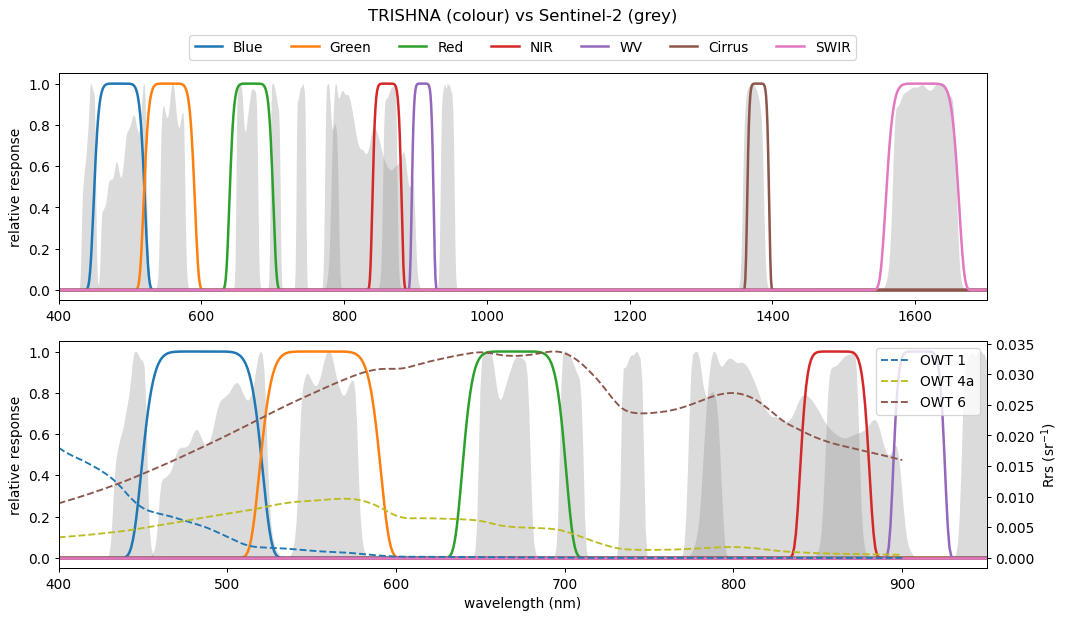

In [3]:
from trishna_tbx import owt
s2 = make_s2()
ref, _ = owt.load_reference('Bi2024')

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, rng in zip(axs, [(400, 1700), (400, 950)]):
    for b in s2.band_names:
        ax.fill_between(s2.srf.wl, s2.srf.sel(band=b), color='0.6', alpha=0.35, lw=0)
    for b in TRISHNA.band_names:
        ax.plot(TRISHNA.srf.wl, TRISHNA.srf.sel(band=b), lw=2, label=b if rng[1] > 1000 else None)
    ax.set_xlim(rng); ax.set_ylabel('relative response')
axr = axs[1].twinx()
for t, c in zip(['1', '4a', '6'], ['tab:blue', 'tab:olive', 'tab:brown']):
    axr.plot(ref.wl, ref.sel(owt=t), c=c, ls='--', label=f'OWT {t}')
axr.set_ylabel('Rrs (sr$^{-1}$)'); axr.legend(loc='upper right')
axs[0].legend(ncol=7, loc='upper center', bbox_to_anchor=(0.5, 1.2))
axs[0].set_title('TRISHNA (colour) vs Sentinel-2 (grey)', y=1.2)
axs[1].set_xlabel('wavelength (nm)')
fig.tight_layout()
fig.savefig(THUMB_DIR / 'trishna_vs_s2_srf.png', dpi=80)

## 3. Closest Sentinel-2 band is not the TRISHNA band
The response-weighted centre of S2 B2 is 496.5 nm, about 11 nm redder than TRISHNA Blue.
S2 B3/B4 are half as wide as TRISHNA Green/Red. Most importantly, the TRISHNA water-vapour
band (910 nm) has **no S2 equivalent**: S2 B9 is centred at 945 nm, in a much deeper
absorption.

In [4]:
def centroid(srf):
    return float((srf * srf.wl).sum() / srf.sum())

def width(srf):
    hi = srf.wl.where(srf >= 0.5 * srf.max(), drop=True)
    return float(hi.max() - hi.min())

rows = []
for b in TRISHNA_BANDS:
    t, s = TRISHNA.srf.sel(band=b.name), s2.srf.sel(band=b.s2_proxy)
    rows.append({'TRISHNA': b.name, 'centre': round(centroid(t), 1), 'FWHM': round(width(t)),
                 'S2 proxy': b.s2_proxy, 'S2 centre': round(centroid(s), 1), 'S2 FWHM': round(width(s)),
                 'shift (nm)': round(centroid(t) - centroid(s), 1)})
pd.DataFrame(rows).set_index('TRISHNA')

,centre,FWHM,S2 proxy,S2 centre,S2 FWHM,shift (nm)
TRISHNA,,,,,,
Blue,485.0,70,B2,496.5,53,-11.5
Green,555.0,70,B3,560.0,34,-5.0
Red,670.0,60,B4,664.4,29,5.6
NIR,860.0,40,B8A,864.8,19,-4.8
WV,910.0,30,B9,945.0,18,-35.0
Cirrus,1380.0,30,B10,1373.5,29,6.5
SWIR,1610.0,100,B11,1613.7,89,-3.7


## 4. What the missing bands mean for water colour
| missing | typical use over water |
|---|---|
| 443 nm (S2 B1) | chlorophyll/CDOM absorption: OC3, QAA, CDOM algorithms |
| 705, 740, 783 nm (S2 B5-B7) | red-edge Chl-a in productive waters (NDCI, Gons, Gilerson), SPM in very turbid waters (Binding) |
| 2190 nm (S2 B12) | aerosol/glint over turbid waters, masking (GRS uses 1610/2190) |

The available bands keep the blue/green ratio (clear-water Chl-a), red and NIR (SPM,
turbidity), and add a 910 nm water-vapour band and the 1380 nm cirrus band.

## 5. Radiometric noise
Noise-equivalent TOA reflectance `NEdrho = pi * L/SNR / (E0 cos(sza))` at sza = 30 deg.
Sentinel-2 bands are degraded to 60 m by averaging 36 (10 m bands) or 9 (20 m bands) pixels,
which reduces white noise by a factor 6 or 3. **Caveat:** the S2 SNR is specified at a
reference radiance (bright) and the TRISHNA one at Lmin (dark): this comparison is indicative.
Rrs noise is roughly `NEdrho / (pi * T)` with T ~ 0.75 the two-way diffuse transmittance.

In [5]:
native = {'B1': 60, 'B2': 10, 'B3': 10, 'B4': 10, 'B5': 20, 'B6': 20, 'B7': 20, 'B8': 10, 'B8A': 20,
          'B9': 60, 'B10': 60, 'B11': 20, 'B12': 20}
n_agg = [(60 // native[b]) ** 2 for b in s2.band_names]
noise = pd.concat({
    'TRISHNA (60 m)': TRISHNA.noise_reflectance(30.).assign_coords(band=TRISHNA.band_names).to_pandas(),
    'S2 native': s2.noise_reflectance(30.).assign_coords(band=s2.band_names).to_pandas(),
    'S2 at 60 m': s2.noise_reflectance(30., n_aggregated=n_agg).assign_coords(band=s2.band_names).to_pandas(),
}, axis=1)
noise['Rrs noise (sr-1)'] = noise.max(axis=1) / (np.pi * 0.75)
(noise * 1e4).round(1).rename(columns=lambda c: c + ' x1e4')

,TRISHNA (60 m) x1e4,S2 native x1e4,S2 at 60 m x1e4,Rrs noise (sr-1) x1e4
band,,,,
Blue,10.9,NaN,NaN,4.6
Green,5.9,NaN,NaN,2.5
Red,4.7,NaN,NaN,2.0
NIR,11.1,NaN,NaN,4.7
WV,24.6,NaN,NaN,10.4
Cirrus,23.6,NaN,NaN,10.0
SWIR,5.8,NaN,NaN,2.5
B1,NaN,18.6,18.6,7.9
B2,NaN,15.4,2.6,6.5


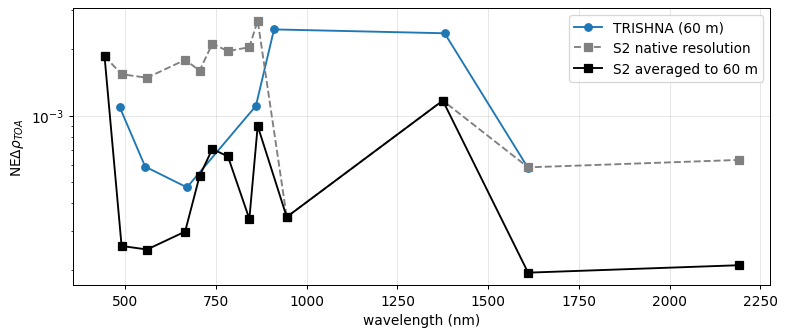

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
x = TRISHNA.centers.values
ax.semilogy(x, noise.loc[TRISHNA.band_names, 'TRISHNA (60 m)'], 'o-', label='TRISHNA (60 m)')
xs = s2.centers.values
ax.semilogy(xs, noise.loc[s2.band_names, 'S2 native'], 's--', c='0.5', label='S2 native resolution')
ax.semilogy(xs, noise.loc[s2.band_names, 'S2 at 60 m'], 's-', c='k', label='S2 averaged to 60 m')
ax.set_xlabel('wavelength (nm)'); ax.set_ylabel('NE$\\Delta\\rho_{TOA}$'); ax.legend(); ax.grid(alpha=.3)

## Take-home messages
- TRISHNA keeps 4 water-colour bands (485/555/670/860 nm), wider than S2, plus WV (910),
  cirrus (1380) and SWIR (1610) for atmospheric correction and masking.
- Algorithms relying on 443 nm or on the red edge cannot be applied as such.
- Emulating TRISHNA by keeping S2 bands is an approximation (band shift/width): see
  *Emulate a TRISHNA L1C from Sentinel-2* and *Top-of-atmosphere simulations with RadCalNet-OC*.
- At requirement level, TRISHNA noise is comparable to or higher than S2 averaged to 60 m,
  in particular in the blue and WV bands.

## References
- TRISHNA mission paper, EGUsphere-2026-4492 (2026), Table 6.
- Bi, S. et al. (2024), optical water types (10 classes), mean spectra from GRSl2bgen.
- ESA, Sentinel-2 MSI spectral responses (COPE-GSEG-EOPG-TN-15-0007).